# Exportar un ProfileReport

In [6]:
from wget import download
from os import path, listdir

if not path.exists('ObesityDataSet_raw_and_data_sinthetic.csv'):
    download("https://ignaciorlando.github.io/datasets/data-science/ObesityDataSet_raw_and_data_sinthetic.csv")
else:
    print("El archivo csv ya existe")

El archivo csv ya existe


### Armado del dataset

In [7]:
import pandas as pd
data_obesity_filter = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

## Histogramas
Con box splot y comun

In [8]:
data_obesity_filter.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   str    
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   str    
 12  FAF                             2111 non-null

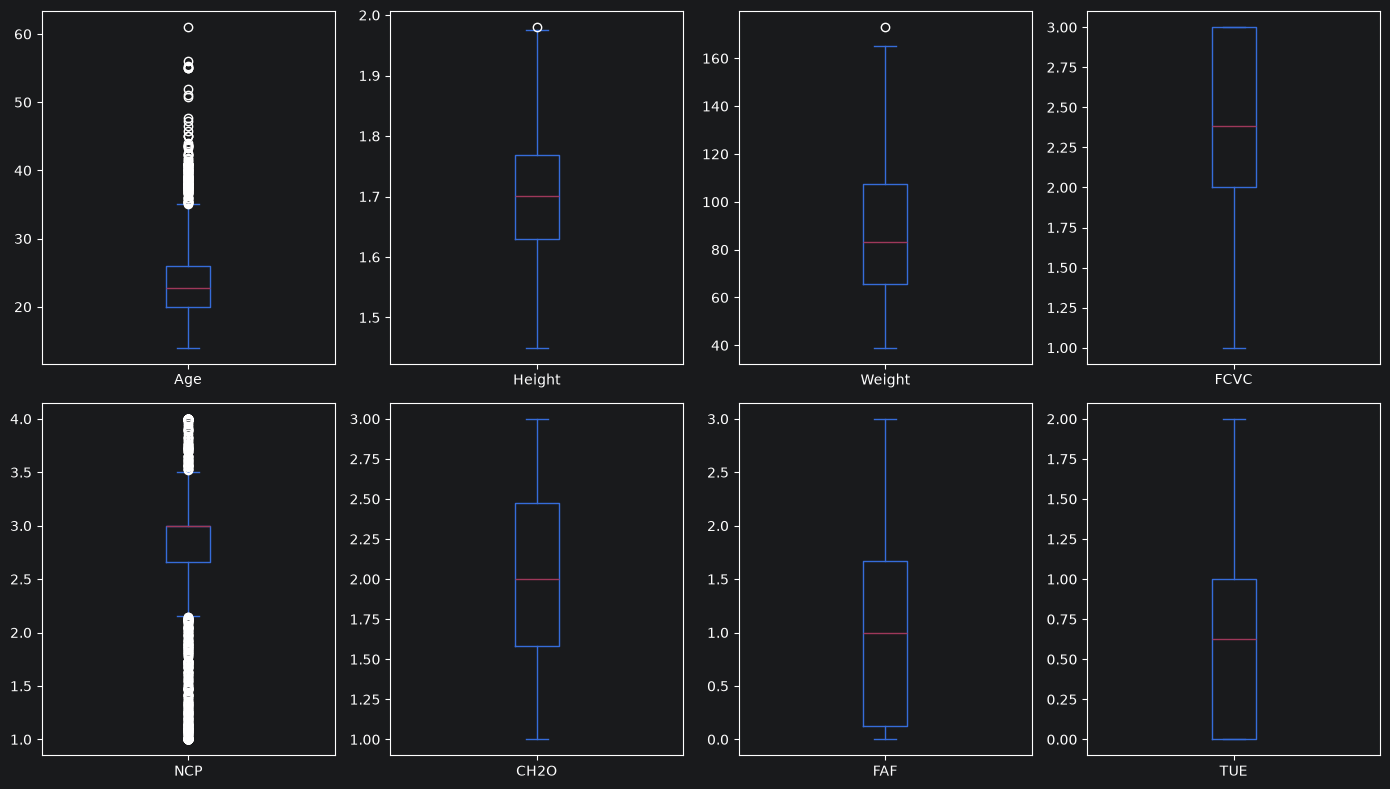

In [9]:
import matplotlib.pyplot as plt
data_obesity_filter.plot(
    kind='box',
    subplots=True,
    layout=(2,4),
    figsize=(14, 8)
)

plt.tight_layout()
plt.show()

Age: age

Height: height

Weight: weight

FCVC: Frequency of consumption of vegetables - Never, Sometimes, Always

NCP: Number of main meals - 1, 2, 3, 4

CH2O: Consumption of water daily - Less than a litter, between 1 and 2 l, more than 2 l

FAF: Physical activity frequency - 0, 1 to 2, 2 to 4, 4 to 5

TUE: Time using technology devices - 0 to 2, 3 to 5, >5


array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Height'}>,
        <Axes: title={'center': 'Weight'}>],
       [<Axes: title={'center': 'FCVC'}>,
        <Axes: title={'center': 'NCP'}>,
        <Axes: title={'center': 'CH2O'}>],
       [<Axes: title={'center': 'FAF'}>, <Axes: title={'center': 'TUE'}>,
        <Axes: >]], dtype=object)

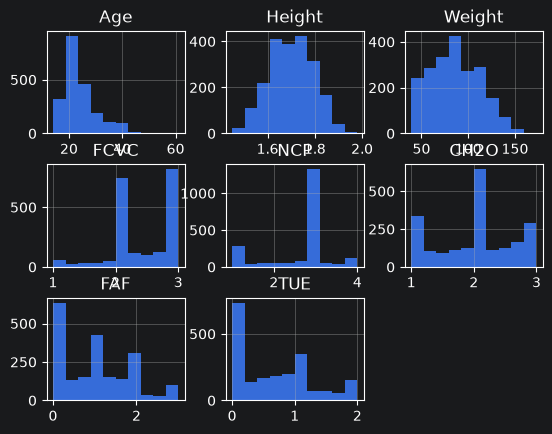

In [5]:
data_obesity_filter.hist()

# Correlacion
Grado y matriz

In [31]:
from scipy import stats

variable_2 = "CH2O"
variable_1 = "FAF"

# Extraer las columnas del DataFrame
datos_columna1 = data_obesity[variable_1]
datos_columna2 = data_obesity[variable_2]

# calcular la correlación de Pearson usando NumPy
#coeficiente_correlacion = np.corrcoef(datos_columna1, datos_columna2)[0, 1]
#print(coeficiente_correlacion)

# alternativamente, se puede usar SciPy:
coeficiente_correlacion, _ = stats.pearsonr(datos_columna1, datos_columna2)
print(f"Correlación entre {variable_1} y {variable_2}: {coeficiente_correlacion:.4f}")

Correlación entre FAF y CH2O: 0.1672


C:\Users\mateo\AppData\Local\Temp\ipykernel_4612\4187719458.py:18: DeprecationWarning: Please import `pearsonr` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  coeficiente_correlacion, _ = stats.pearsonr(data_obesity[variable_1], data_obesity[variable_2])


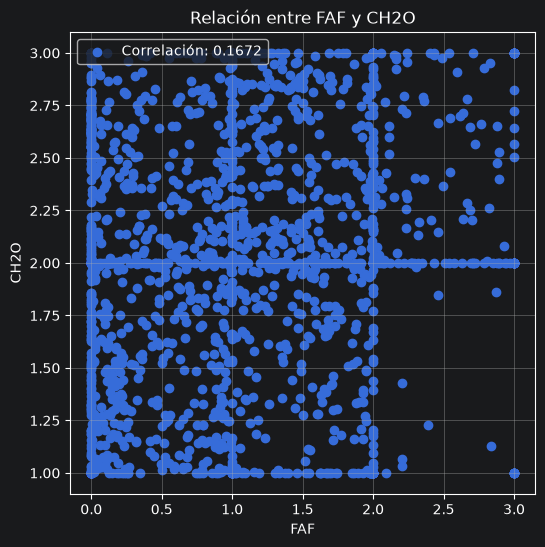

In [23]:
from scipy.stats import stats
import matplotlib.pyplot as plt

variable_2 = "CH2O"
variable_1 = "FAF"
# en clase, mostrar también este ejemplo
#variable_1 = "CHAS"
#variable_2 = "NOX"

# creamos el scatter plot
plt.figure(figsize=(6, 6))  # con esta línea podemos ajustar el tamaño de la gráfica
plt.scatter(data_obesity[variable_1], data_obesity[variable_2])
plt.xlabel(variable_1)
plt.ylabel(variable_2)
plt.title("Relación entre {} y {}".format(variable_1, variable_2))

# calcular la correlación de Pearson usando SciPy
coeficiente_correlacion, _ = stats.pearsonr(data_obesity[variable_1], data_obesity[variable_2])
# agregar la leyenda con el valor del coeficiente de correlación
plt.legend([f"Correlación: {coeficiente_correlacion:.4f}"], loc="upper left")

# Mostrar el gráfico
plt.grid(True)
plt.show()

In [42]:
correlation_matrix = data_obesity.corr(numeric_only=True)
correlation_matrix

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Age,1.000000,-0.025958,0.202560,0.016291,-0.043944,-0.045304,-0.144938,-0.296931
Height,-0.025958,1.000000,0.463136,-0.038121,0.243672,0.213376,0.294709,0.051912
Weight,0.202560,0.463136,1.000000,0.216125,0.107469,0.200575,-0.051436,-0.071561
FCVC,0.016291,-0.038121,0.216125,1.000000,0.042216,0.068461,0.019939,-0.101135
NCP,-0.043944,0.243672,0.107469,0.042216,1.000000,0.057088,0.129504,0.036326
CH2O,-0.045304,0.213376,0.200575,0.068461,0.057088,1.000000,0.167236,0.011965
FAF,-0.144938,0.294709,-0.051436,0.019939,0.129504,0.167236,1.000000,0.058562
TUE,-0.296931,0.051912,-0.071561,-0.101135,0.036326,0.011965,0.058562,1.000000


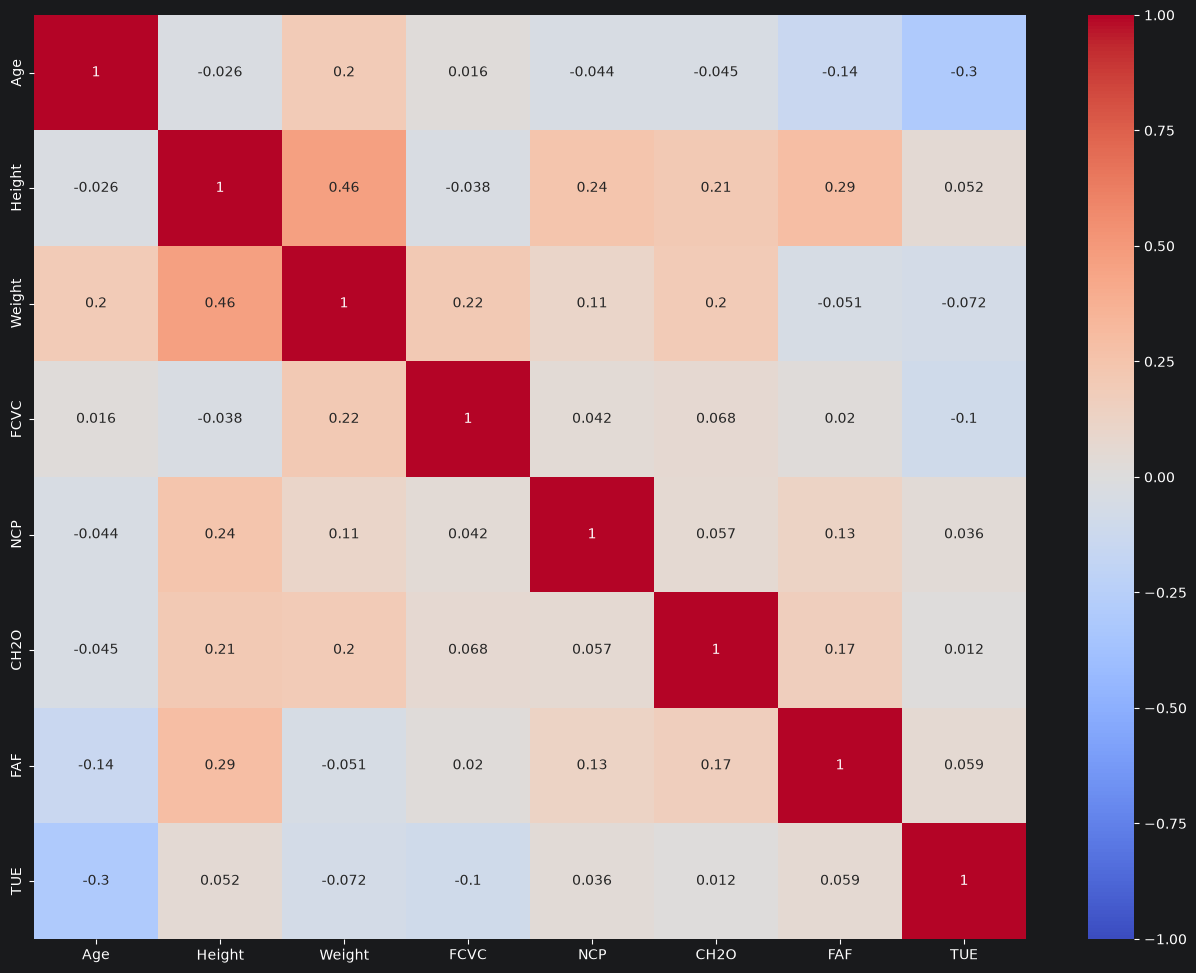

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

# imprimimos la matriz como un heatmap
plt.figure(figsize=(16,12))
sns.heatmap(correlation_matrix, vmin=-1.0, vmax=1.0, center=0.0, annot=True, cmap= 'coolwarm')
plt.show()

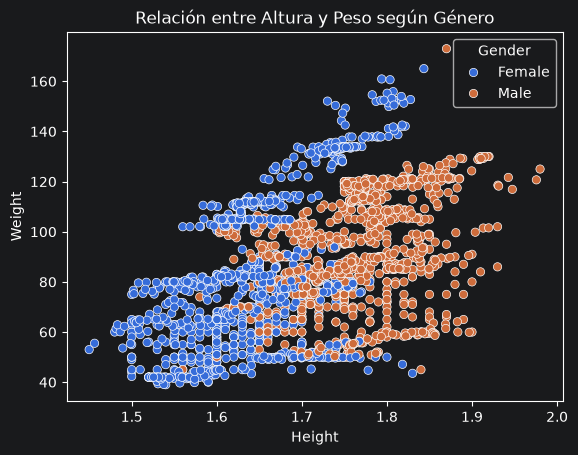

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Comparamos Altura y Peso (dos numéricas), coloreadas por Género (una cualitativa)
sns.scatterplot(data=data_obesity_filter, x='Height', y='Weight', hue= "Gender")

plt.title('Relación entre Altura y Peso según Género')
plt.show()

## Relacion entre la gordura familiar y el peso

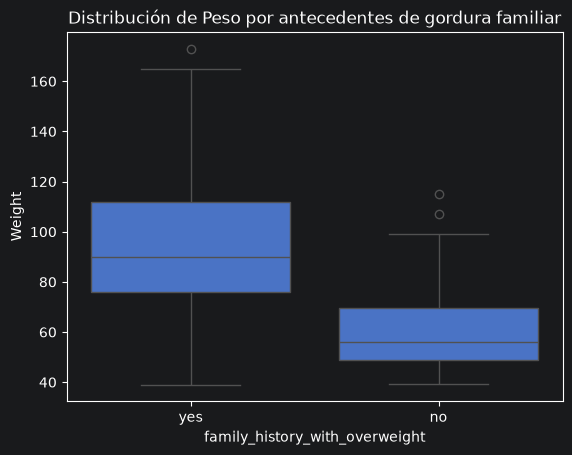

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

colores = {'yes': '#DB2B07', 'no': '#99CCFF'}
sns.boxplot(data=data_obesity_filter, x='family_history_with_overweight', y='Weight',hue= "family_history_with_overweight")

plt.title('Distribución de Peso por antecedentes de gordura familiar')
plt.show()

In [9]:
data_obesity_filter.columns

Index(['Age', 'Gender', 'Height', 'Weight', 'CALC', 'FAVC', 'FCVC', 'NCP',
       'SCC', 'SMOKE', 'CH2O', 'family_history_with_overweight', 'FAF', 'TUE',
       'CAEC', 'MTRANS', 'NObeyesdad'],
      dtype='str')